## **Lab 8: KNN, K-means, Hierarchical Clustering, and K-Prototypes**
### Fiona St. Clair

AI Disclosure: Claude Sonnet AI was used to help adapt the code from the instructions, class slideshows, and class notebooks into this lab. The written responses are my own logical and reasoning. 
***

## Part 1: K-Nearest Neighbors

### Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (accuracy_score, recall_score, precision_score, roc_auc_score,
                             silhouette_score, ConfusionMatrixDisplay, RocCurveDisplay)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")

In [2]:
framingham = pd.read_csv("../../../data/framingham.csv")

features = ["male", "age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
target = "TenYearCHD"

# KNN needs complete rows: drop patients missing any of these columns
fram = framingham.dropna(subset=features + [target]).reset_index(drop=True)
X = fram[features]
y = fram[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)


def make_knn(k):
    return Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=k))])

print(f"{len(framingham)} patients, {len(fram)} with complete data")

4240 patients, 3802 with complete data


### 1. Baselines

In [3]:
# "Model" that predicts no CHD for every training patient
never = np.zeros(len(y_train), dtype=int)
print(f"CHD rate in training set: {y_train.mean():.3f}")
print(f"Accuracy: {accuracy_score(y_train, never):.3f}")
print(f"Recall for CHD: {recall_score(y_train, never):.3f}")
print(f"ROC AUC: {roc_auc_score(y_train, never):.3f}")

CHD rate in training set: 0.153
Accuracy: 0.847
Recall for CHD: 0.000
ROC AUC: 0.500


**1 - What would be this model's recall for CHD and its ROC AUC?**

**Recall for CHD is 0, because the model never predicts CHD. ROC AUC is 0.5, because giving every patient the same score can't rank anyone above anyone else.**

### 2. Choosing k

In [4]:
k_values = [1, 5, 11, 25, 51, 75, 101, 151, 201, 251, 301]

rows = []
for k in k_values:
    res = cross_validate(make_knn(k), X_train, y_train, cv=cv,
                         scoring=["accuracy", "balanced_accuracy", "roc_auc"])
    rows.append({"k": k,
                 "accuracy": res["test_accuracy"].mean(),
                 "balanced accuracy": res["test_balanced_accuracy"].mean(),
                 "ROC AUC": res["test_roc_auc"].mean(),
                 "ROC AUC (sd)": res["test_roc_auc"].std()})
knn_results = pd.DataFrame(rows).set_index("k")
knn_results.round(4)

,accuracy,balanced accuracy,ROC AUC,ROC AUC (sd)
k,,,,
1,0.7715,0.5470,0.5470,0.0168
5,0.8333,0.5404,0.6131,0.0243
11,0.8451,0.5193,0.6422,0.0212
25,0.8461,0.5014,0.6678,0.0232
51,0.8468,0.5000,0.6811,0.0185
75,0.8468,0.5000,0.6901,0.0218
101,0.8468,0.5000,0.6966,0.0195
151,0.8468,0.5000,0.7001,0.0176
201,0.8468,0.5000,0.7053,0.0159


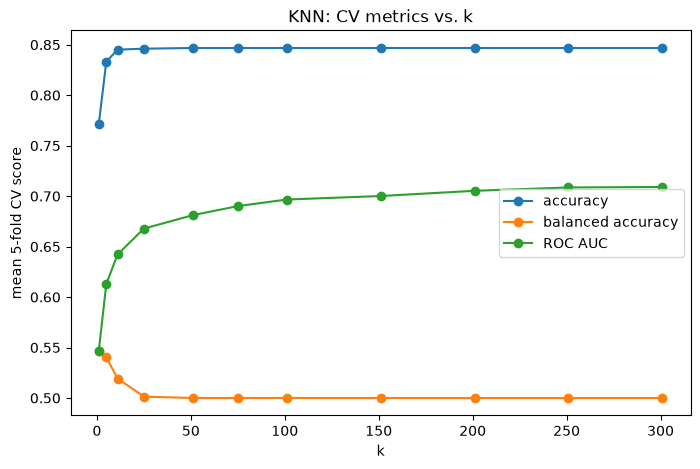

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for col in ["accuracy", "balanced accuracy", "ROC AUC"]:
    ax.plot(knn_results.index, knn_results[col], marker="o", label=col)
ax.set(xlabel="k", ylabel="mean 5-fold CV score", title="KNN: CV metrics vs. k")
ax.legend()
plt.show()

#### a. Accuracy

In [6]:
best_acc_k = knn_results["accuracy"].idxmax()
print(f"k with the highest CV accuracy: {best_acc_k} ({knn_results.loc[best_acc_k, 'accuracy']:.4f})")

# How many training patients does each model predict will develop CHD? (out-of-fold)
for k in [11, 51, 151]:
    pred = cross_val_predict(make_knn(k), X_train, y_train, cv=cv)
    print(f"k = {k:>3}: predicts CHD for {pred.sum()} of {len(y_train)} patients")

k with the highest CV accuracy: 51 (0.8468)
k =  11: predicts CHD for 51 of 3041 patients
k =  51: predicts CHD for 0 of 3041 patients
k = 151: predicts CHD for 0 of 3041 patients


**2a - Which k has the highest CV accuracy? How many patients does each model predict will develop CHD? Why does accuracy rise with k and then stop changing at the value from Q1?**

**k = 51 has the highest CV accuracy (0.8468). The k = 11 model predicts CHD for 51 of the 3,041 training patients, and the k = 51 and k = 151 models predict it for 0. Small k chases noise and flags some patients as CHD who aren't, which costs accuracy. As k grows, fewer patients get flagged until none do, and then accuracy is just the no-CHD baseline from Q1 (about 85%), which can't change.**

#### b. Balanced accuracy

**2b - What happens to balanced accuracy as k grows, and why?**

**Balanced accuracy drops from 0.547 at k = 1 down to exactly 0.5 for every k from 51 on. Once the model stops predicting CHD, recall for CHD is 0 and recall for no CHD is 1, so the average is 0.5, the same as guessing.**

#### c. ROC AUC and the one-standard-error rule

In [7]:
best_k = knn_results["ROC AUC"].idxmax()
best_auc = knn_results.loc[best_k, "ROC AUC"]
se = knn_results.loc[best_k, "ROC AUC (sd)"] / np.sqrt(5)

# Smallest k whose mean AUC is within one SE of the best
k_1se = knn_results.index[knn_results["ROC AUC"] >= best_auc - se].min()

print(f"Highest CV ROC AUC: k = {best_k} ({best_auc:.4f}), SE = {se:.4f}")
print(f"Cutoff (best - 1 SE): {best_auc - se:.4f}")
print(f"One-standard-error k: {k_1se} (AUC = {knn_results.loc[k_1se, 'ROC AUC']:.4f})")

Highest CV ROC AUC: k = 301 (0.7091), SE = 0.0098
Cutoff (best - 1 SE): 0.6993
One-standard-error k: 151 (AUC = 0.7001)


**2c - Which k has the highest CV ROC AUC? What is the smallest k within one standard error of the best?**

**k = 301 has the highest CV ROC AUC (0.7091, SE = 0.0098). The cutoff is 0.6993, and the smallest k above it is k = 151 (AUC 0.7001), so I use k = 151 for the rest of Part 1.**

### 3. Choosing a threshold

In [8]:
k = k_1se
oof_prob = cross_val_predict(make_knn(k), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

print(f"k = {k}")
print(f"Highest out-of-fold predicted probability of CHD: {oof_prob.max():.3f}")
print(f"Patients with predicted probability >= 0.5: {(oof_prob >= 0.5).sum()} of {len(oof_prob)}")

k = 151
Highest out-of-fold predicted probability of CHD: 0.404
Patients with predicted probability >= 0.5: 0 of 3041


**3a - Why does the default predict(), which uses a threshold of 0.5, never predict CHD?**

**Each predicted probability is the share of the 151 nearest neighbors with CHD. Only about 15% of patients have CHD, so almost no neighborhood is 50% CHD. The highest predicted probability is 0.404, so nobody reaches 0.5.**

#### b. Confusion matrices at thresholds of 0.5 and 0.2

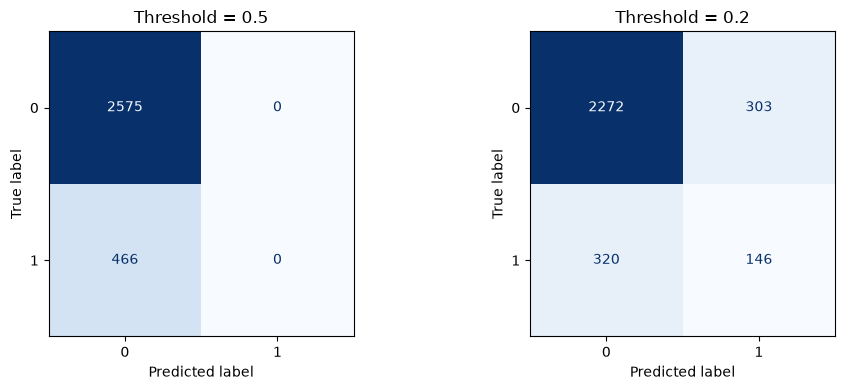

,accuracy,recall (CHD),precision (CHD)
threshold 0.5,0.847,0.000,0.000
threshold 0.2,0.795,0.313,0.325


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
summary = {}
for ax, t in zip(axes, [0.5, 0.2]):
    pred = (oof_prob >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_train, pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Threshold = {t}")
    summary[f"threshold {t}"] = {"accuracy": accuracy_score(y_train, pred),
                                 "recall (CHD)": recall_score(y_train, pred),
                                 "precision (CHD)": precision_score(y_train, pred, zero_division=0)}
plt.tight_layout()
plt.show()
pd.DataFrame(summary).T.round(3)

**3b - Which threshold would be more useful for a doctor deciding whom to follow up with? Why does it make sense to choose k by ROC AUC and then choose the threshold separately?**

**At 0.5 the model has recall 0 and accuracy 0.847. At 0.2 recall is 0.313, precision is 0.325, and accuracy drops to 0.795. A doctor would want 0.2, because catching 31% of CHD cases beats catching none, and an extra follow-up visit costs much less than a missed case. ROC AUC measures how well the model ranks patients over all thresholds, so it's a fair way to pick k. The right threshold depends on how bad a miss is versus a false alarm, which is a separate decision.**

### 4. Evaluate on the test set

Test ROC AUC: 0.7664
CV ROC AUC (k = 151): 0.7001
At threshold 0.2 -> accuracy: 0.798, recall: 0.436, precision: 0.367
Test set: 761 patients, 117 with CHD


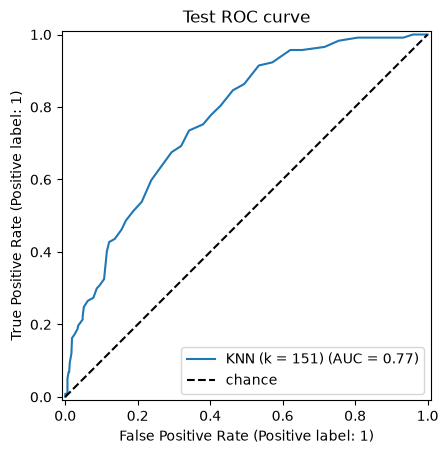

In [10]:
final_knn = make_knn(k_1se).fit(X_train, y_train)
test_prob = final_knn.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.2).astype(int)

print(f"Test ROC AUC: {roc_auc_score(y_test, test_prob):.4f}")
print(f"CV ROC AUC (k = {k_1se}): {knn_results.loc[k_1se, 'ROC AUC']:.4f}")
print(f"At threshold 0.2 -> accuracy: {accuracy_score(y_test, test_pred):.3f}, "
      f"recall: {recall_score(y_test, test_pred):.3f}, precision: {precision_score(y_test, test_pred):.3f}")
print(f"Test set: {len(y_test)} patients, {y_test.sum()} with CHD")

RocCurveDisplay.from_predictions(y_test, test_prob, name=f"KNN (k = {k_1se})")
plt.plot([0, 1], [0, 1], "k--", label="chance")
plt.legend()
plt.title("Test ROC curve")
plt.show()

**4a - Report the test ROC AUC, and the accuracy, recall, and precision at a threshold of 0.2.**

**Test ROC AUC is 0.766. At a threshold of 0.2, accuracy is 0.798, recall is 0.436, and precision is 0.367.**

**4b - How does the test ROC AUC compare with the CV ROC AUC? Is the difference large enough to change your conclusions? Would it be appropriate to go back and pick a different k now?**

**Test AUC (0.766) is higher than CV AUC (0.700). With only 117 CHD cases in the test set, that estimate is noisy, so some of the gap is probably luck. It doesn't change the conclusion: KNN ranks patients better than chance but only modestly. Going back to pick a different k would not be appropriate, because the test set would no longer be a fair, untouched check.**

***
## Part 2: K-means Clustering

### Setup

In [11]:
auto = pd.read_csv("../../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

auto_feats = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
Xa = auto[auto_feats]

scaler = StandardScaler()
Xa_s = scaler.fit_transform(Xa)   # 392 cars x 5 standardized features (a NumPy array)
print(auto.shape)

(392, 9)


In [12]:
# Helper from the in-class notebook: number clusters 1, 2, 3, ... in order of the average of `values`
def renumber(labels, values, ascending=True):
    order = pd.Series(np.asarray(values)).groupby(np.asarray(labels)).mean().sort_values(ascending=ascending).index.to_numpy()
    new_number = {old: i + 1 for i, old in enumerate(order)}
    return np.array([new_number[k] for k in labels]), order

### 1. Scaling

#### a. Summary table

In [13]:
Xa.describe().T[["mean", "std", "min", "max"]].round(1)

,mean,std,min,max
mpg,23.4,7.8,9.0,46.6
displacement,194.4,104.6,68.0,455.0
horsepower,104.5,38.5,46.0,230.0
weight,2977.6,849.4,1613.0,5140.0
acceleration,15.5,2.8,8.0,24.8


#### b. K-means on the unscaled features

Range of weight in each cluster:
         count   min   max
cluster                   
1          180  1613  2694
2          122  2700  3672
3           90  3693  5140


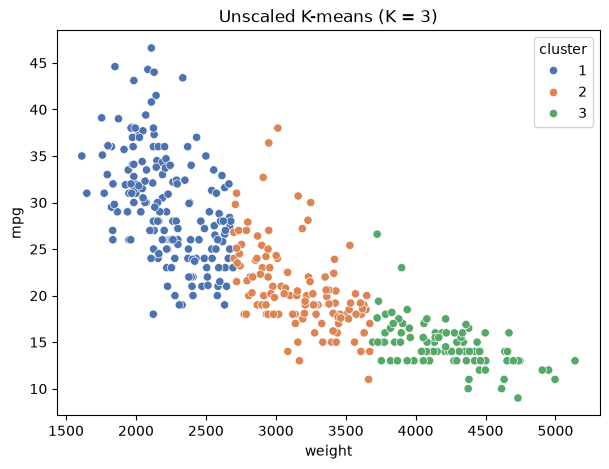

In [14]:
km_raw = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Xa)
raw_labels, _ = renumber(km_raw.labels_, auto["weight"])

print("Range of weight in each cluster:")
print(auto.assign(cluster=raw_labels).groupby("cluster")["weight"].agg(["count", "min", "max"]))

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=auto["weight"], y=auto["mpg"], hue=raw_labels, palette="deep", ax=ax)
ax.set_title("Unscaled K-means (K = 3)")
ax.legend(title="cluster")
plt.show()

**1b - What did K-means do, and why?**

**K-means just cut the cars into three weight bands (1613-2694, 2700-3672, 3693-5140 lbs). Weight is in the thousands (SD 849), while mpg and acceleration have SDs of 7.8 and 2.8, so weight dominates the Euclidean distance and the other features barely count. Standardizing fixes this.**

### 2. Choosing K

In [15]:
rows = []
for K in range(1, 11):
    m = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Xa_s)
    rows.append({"K": K, "WCSS": m.inertia_,
                 "avg silhouette": silhouette_score(Xa_s, m.labels_) if K > 1 else np.nan})
choose_k = pd.DataFrame(rows).set_index("K")
choose_k.round(3)

,WCSS,avg silhouette
K,,
1,1960.000,NaN
2,834.029,0.524
3,561.671,0.382
4,451.322,0.360
5,388.114,0.348
6,333.871,0.322
7,300.501,0.313
8,274.951,0.298
9,257.563,0.277


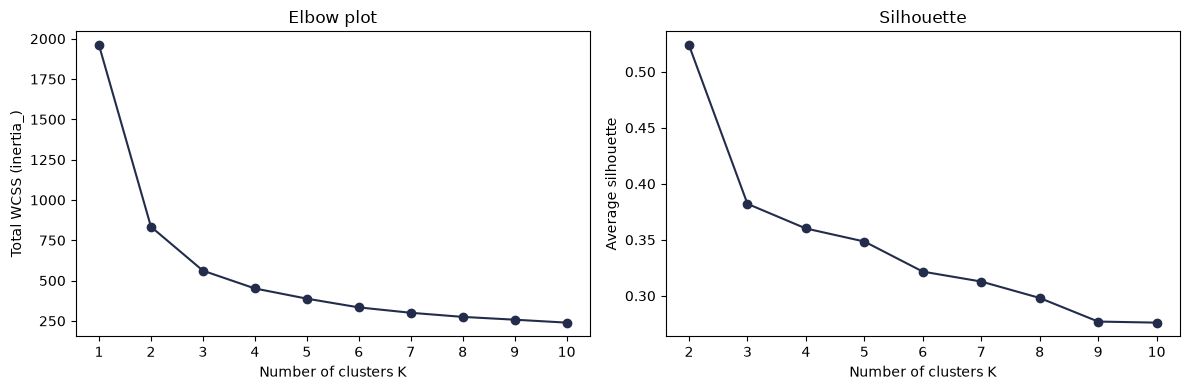

Largest average silhouette: K = 2 (0.524)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(choose_k.index, choose_k["WCSS"], marker="o", color="#232D4B")
axes[0].set(xlabel="Number of clusters K", ylabel="Total WCSS (inertia_)", title="Elbow plot", xticks=range(1, 11))
axes[1].plot(choose_k.index[1:], choose_k["avg silhouette"].iloc[1:], marker="o", color="#232D4B")
axes[1].set(xlabel="Number of clusters K", ylabel="Average silhouette", title="Silhouette", xticks=range(2, 11))
plt.tight_layout()
plt.show()

best_K = choose_k["avg silhouette"].idxmax()
print(f"Largest average silhouette: K = {best_K} ({choose_k.loc[best_K, 'avg silhouette']:.3f})")

**2a - Where is the elbow in the WCSS plot?**

**The elbow is at K = 3. WCSS falls a lot from K = 1 to 2 to 3 (1960, 834, 562) and then flattens (451, 388).**

**2b - Which K has the largest average silhouette?**

**K = 2 has the largest average silhouette (0.524).**

**2c - Which K would you choose?**

**I would choose K = 3. K = 2 has the best silhouette but only splits big 8-cylinder cars from everything else. K = 3 sits at the elbow and gives a more useful small / medium / large split.**

### 3. Interpreting K = 3

In [17]:
km3 = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Xa_s)
auto["km3"], _ = renumber(km3.labels_, auto["weight"])   # 1 = lightest, 3 = heaviest

#### a. Cluster profile (original units)

In [18]:
profile3 = auto.groupby("km3")[auto_feats].mean().round(1)
profile3.insert(0, "n cars", auto["km3"].value_counts().sort_index())
profile3

,n cars,mpg,displacement,horsepower,weight,acceleration
km3,,,,,,
1,147,31.6,103.2,72.9,2189.8,16.8
2,148,21.2,184.3,98.3,2995.6,16.2
3,97,14.5,348.0,161.8,4144.0,12.6


#### b. Compare with variables we left out

In [19]:
print("Clusters vs. cylinders")
display(pd.crosstab(auto["km3"], auto["cylinders"]))
print("Clusters vs. origin (1 = American, 2 = European, 3 = Japanese)")
display(pd.crosstab(auto["km3"], auto["origin"]))
print("Mean model year")
auto.groupby("km3")["year"].mean().round(1)

Clusters vs. cylinders


cylinders,3,4,5,6,8
km3,,,,,
1,0,144,1,2,0
2,4,55,2,80,7
3,0,0,0,1,96


Clusters vs. origin (1 = American, 2 = European, 3 = Japanese)


origin,1,2,3
km3,,,
1,44,45,58
2,104,23,21
3,97,0,0


Mean model year


km3
1    77.6
2    75.9
3    73.6
Name: year, dtype: float64

**3b - Which cluster is entirely American? Where do the four-cylinder cars end up? Does the clustering line up with any variable we left out?**

**Cluster 3 (the heavy, 14.5 mpg cars) is entirely American, with 97 of 97 cars from origin 1. The four-cylinder cars mostly land in cluster 1 (144 of 199), and the other 55 are in cluster 2. The clusters line up best with cylinders: cluster 1 is four-cylinder, cluster 3 is eight-cylinder, and cluster 2 is mostly six-cylinder with some fours. They also line up with model year, from newer (77.6) in cluster 1 to older (73.6) in cluster 3.**

### 4. Interpreting K = 2

In [20]:
km2 = KMeans(n_clusters=2, n_init=20, random_state=0).fit(Xa_s)
auto["km2"], _ = renumber(km2.labels_, auto["weight"])

#### a. K = 2 vs. K = 3 and cylinders

In [21]:
print("K = 2 vs. K = 3")
display(pd.crosstab(auto["km2"], auto["km3"]))
print("K = 2 vs. cylinders")
pd.crosstab(auto["km2"], auto["cylinders"])

K = 2 vs. K = 3


km3,1,2,3
km2,,,
1,147,144,0
2,0,4,97


K = 2 vs. cylinders


cylinders,3,4,5,6,8
km2,,,,,
1,4,199,3,81,4
2,0,0,0,2,99


**4a - What does the K = 2 solution separate?**

**K = 2 separates the big eight-cylinder cars (cluster 2: 99 of its 101 cars) from the smaller four- and six-cylinder cars.**

**4b - Are the K = 2 and K = 3 solutions nested? Does K-means have to give nested solutions?**

**Almost, but not exactly. K = 2 cluster 1 holds all of K = 3 clusters 1 and 2 except 4 cars, which sit in K = 2 cluster 2 with the heavy cars. K-means doesn't have to be nested because each K is fit from scratch with its own centers. Hierarchical clustering is always nested.**

***
## Part 3: Hierarchical Clustering

### 1. Linkage

In [22]:
rows = {}
for link in ["single", "complete", "average", "ward"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(Xa_s)
    rows[f"{link} linkage"] = {"cluster sizes": sorted(np.bincount(lab), reverse=True),
                               "avg silhouette": round(silhouette_score(Xa_s, lab), 3)}
rows["K-means (K = 3)"] = {"cluster sizes": sorted(np.bincount(km3.labels_), reverse=True),
                           "avg silhouette": round(silhouette_score(Xa_s, km3.labels_), 3)}
pd.DataFrame(rows).T

,cluster sizes,avg silhouette
single linkage,"[390, 1, 1]",-0.059
complete linkage,"[200, 97, 95]",0.343
average linkage,"[291, 97, 4]",0.422
ward linkage,"[212, 99, 81]",0.374
K-means (K = 3),"[148, 147, 97]",0.382


**1a - Which linkage rules give very lopsided clusters?**

**Single linkage ([390, 1, 1]) is very lopsided, and average linkage ([291, 97, 4]) is lopsided too. Complete and Ward are much more balanced.**

#### b. The two small single-linkage clusters

In [23]:
single_lab = AgglomerativeClustering(n_clusters=3, linkage="single").fit_predict(Xa_s)
big = np.bincount(single_lab).argmax()
small = auto[single_lab != big].assign(single_cluster=single_lab[single_lab != big])
print(small[["name", "year", "single_cluster"] + auto_feats].to_string())
print()
print("For comparison, the average car:")
print(Xa.mean().round(1).to_string())

                                  name  year  single_cluster   mpg  displacement  horsepower  weight  acceleration
13             buick estate wagon (sw)    70               2  14.0         455.0       225.0    3086          10.0
381  oldsmobile cutlass ciera (diesel)    82               1  38.0         262.0        85.0    3015          17.0

For comparison, the average car:
mpg               23.4
displacement     194.4
horsepower       104.5
weight          2977.6
acceleration      15.5


**1b - Why are these cars unusual? Why does single linkage give each of them its own cluster?**

**These are the 1970 Buick Estate Wagon and the 1982 Oldsmobile Cutlass Ciera (diesel). The Buick has one of the biggest engines in the data (455 cu in, 225 hp) in a 3,086 lb car, and the Ciera gets 38 mpg despite a 262 cu in engine and 3,015 lbs. Each has a combination of features no other car has. Single linkage merges clusters by their closest pair of cars, and these two are far from every other car, so they are the last to join and stay alone.**

#### c. Silhouette

**1c - Which method has the highest average silhouette? Does that make it the best clustering of these cars?**

**Average linkage has the highest silhouette (0.422), but that doesn't make it the best. Its clusters are [291, 97, 4], so one cluster is only 4 cars, and a tiny tight cluster is easy for the silhouette to reward. Ward (0.374) and K-means (0.382) have lower silhouettes but much more useful clusters.**

### 2. The Ward tree

#### a. Full dendrogram and cutting the tree

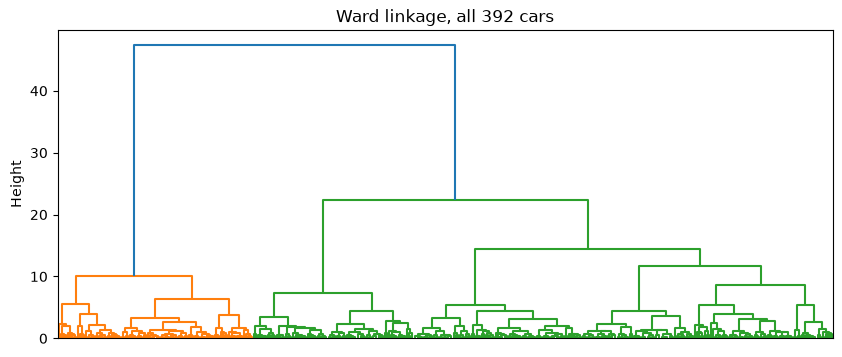

Eight largest merge heights: [47.39 22.43 14.5  11.64 10.08  8.56  7.27  6.33]

Jump between consecutive merges (cutting just below the higher merge):
1 -> 2 clusters    24.97
2 -> 3 clusters     7.93
3 -> 4 clusters     2.86
4 -> 5 clusters     1.55
5 -> 6 clusters     1.52
6 -> 7 clusters     1.29
7 -> 8 clusters     0.94


In [24]:
Z = linkage(Xa_s, method="ward")

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, no_labels=True, ax=ax)
ax.set(title="Ward linkage, all 392 cars", ylabel="Height")
plt.show()

heights = Z[:, 2]
top8 = heights[-8:][::-1]          # eight largest merge heights, biggest first
print("Eight largest merge heights:", top8.round(2))
jumps = pd.Series(top8[:-1] - top8[1:], index=[f"{i+1} -> {i+2} clusters" for i in range(7)])
print()
print("Jump between consecutive merges (cutting just below the higher merge):")
print(jumps.round(2).to_string())

In [25]:
# Cut at K = 2, ..., 8 and compute the silhouette
cuts = {K: fcluster(Z, t=K, criterion="maxclust") for K in range(2, 9)}
ward_sil = pd.DataFrame({"Ward avg silhouette": {K: silhouette_score(Xa_s, lab) for K, lab in cuts.items()},
                         "K-means avg silhouette": choose_k["avg silhouette"].loc[2:8]})
ward_sil.index.name = "K"
ward_sil.round(3)

,Ward avg silhouette,K-means avg silhouette
K,,
2,0.525,0.524
3,0.374,0.382
4,0.313,0.360
5,0.327,0.348
6,0.291,0.322
7,0.295,0.313
8,0.263,0.298


**2a - Where is the largest jump between consecutive merges, and how many clusters do you get by cutting there? Where is the second largest? Do the silhouette results agree with K-means from Part 2, Q2?**

**The largest jump is from 47.4 to 22.4 (about 25), so cutting there gives 2 clusters. The second largest is from 22.4 to 14.5 (about 7.9), which gives 3 clusters. The Ward silhouette is highest at K = 2 (0.525) and next best at K = 3 (0.374), the same as K-means (0.524 and 0.382). So the two methods agree: 2 is best, 3 is the runner-up.**

#### b. Dendrogram of 30 random cars

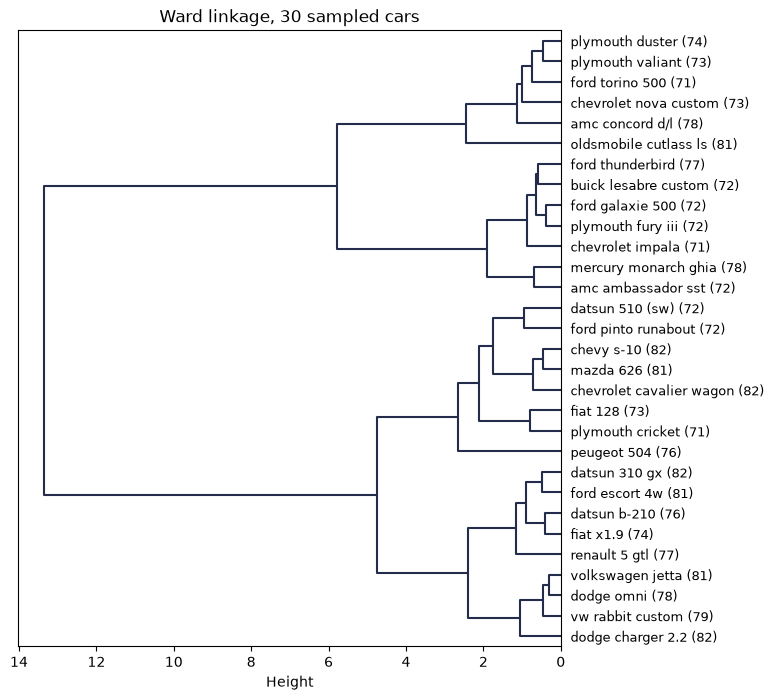

In [26]:
# Q2b: 30 cars sampled at random, labeled by name and model year.
rng = np.random.default_rng(6021)
samp = np.sort(rng.choice(len(auto), 30, replace=False))
names = (auto.loc[samp, "name"] + " (" + auto.loc[samp, "year"].astype(str) + ")").to_list()

fig, ax = plt.subplots(figsize=(7, 8))
dendrogram(linkage(Xa_s[samp], method="ward"), labels=names, orientation="left",
           color_threshold=0, above_threshold_color="#232D4B", leaf_font_size=9, ax=ax)
ax.set(xlabel="Height", title="Ward linkage, 30 sampled cars")
plt.show()

**2b - Which two cars are merged first? If you cut this small tree into three clusters, how would you describe each group? Does any car seem out of place?**

**The Dodge Omni (78) and Volkswagen Jetta (81) merge first (height 0.30), which makes sense because they're nearly identical small cars. Cutting into three clusters gives: (1) 17 small four-cylinder cars (about 30 mpg, 2,245 lbs), (2) 7 big eight-cylinder American cars (about 16 mpg, 4,079 lbs), and (3) 6 mid-size cars (about 20 mpg, 3,323 lbs). The Peugeot 504 (76) is a bit out of place in the small group because it weighs 3,270 lbs with 19 mpg, and the Oldsmobile Cutlass LS (81) is an eight-cylinder with 26.6 mpg sitting in the mid-size group.**

### 3. Ward linkage vs. K-means

In [27]:
auto["ward2"] = fcluster(Z, t=2, criterion="maxclust")
auto["ward3"] = fcluster(Z, t=3, criterion="maxclust")
# Number the Ward clusters by weight so 1 = lightest (same as K-means)
auto["ward2"], _ = renumber(auto["ward2"], auto["weight"])
auto["ward3"], _ = renumber(auto["ward3"], auto["weight"])

for K in [2, 3]:
    ct = pd.crosstab(auto[f"ward{K}"], auto[f"km{K}"])
    print(f"Ward (rows) vs. K-means (columns), K = {K}")
    display(ct)
    print(f"Cars where the methods agree: {ct.max(axis=1).sum()} of {len(auto)}\n")

Ward (rows) vs. K-means (columns), K = 2


km2,1,2
ward2,,
1,291,2
2,0,99


Cars where the methods agree: 390 of 392

Ward (rows) vs. K-means (columns), K = 3


km3,1,2,3
ward3,,,
1,147,65,0
2,0,81,0
3,0,2,97


Cars where the methods agree: 325 of 392



#### b. Cylinders and disagreements

In [28]:
print("Ward K = 3 vs. cylinders")
display(pd.crosstab(auto["ward3"], auto["cylinders"]))
print("K-means K = 3 vs. cylinders")
display(pd.crosstab(auto["km3"], auto["cylinders"]))

# Cars on which Ward and K-means disagree (K = 3). Clusters were numbered by weight, so the labels match.
disagree = auto[auto["ward3"] != auto["km3"]]
print(f"{len(disagree)} cars disagree")
print("Cylinders of the disagreeing cars:")
display(disagree["cylinders"].value_counts().sort_index().to_frame("cars"))
print("Average features, disagreeing cars vs. all cars:")
pd.DataFrame({"disagreeing cars": disagree[auto_feats].mean(), "all cars": auto[auto_feats].mean()}).round(1)

Ward K = 3 vs. cylinders


cylinders,3,4,5,6,8
ward3,,,,,
1,4,195,2,11,0
2,0,4,1,70,6
3,0,0,0,2,97


K-means K = 3 vs. cylinders


cylinders,3,4,5,6,8
km3,,,,,
1,0,144,1,2,0
2,4,55,2,80,7
3,0,0,0,1,96


67 cars disagree
Cylinders of the disagreeing cars:


,cars
cylinders,
3,4
4,51
5,1
6,10
8,1


Average features, disagreeing cars vs. all cars:


,disagreeing cars,all cars
mpg,23.6,23.4
displacement,136.8,194.4
horsepower,95.5,104.5
weight,2676.5,2977.6
acceleration,15.7,15.5


**3a - On how many of the 392 cars do the two methods agree (K = 2 and K = 3)?**

**At K = 2 they agree on 390 of 392 cars. At K = 3 they agree on 325 of 392 cars.**

**3b - Which method's clusters line up better with cylinder count? Describe the cars on which Ward and K-means disagree.**

**Ward lines up better with cylinders. Its clusters are mostly 4-cylinder (195 of 212), 6-cylinder (70 of 81), and 8-cylinder (97 of 99). K-means mixes 55 four-cylinder and 80 six-cylinder cars in its middle cluster. They disagree on 67 cars, and 51 of those are four-cylinder. They are on the light side (about 2,677 lbs, 137 displacement vs. 2,978 and 194 overall). Ward puts them in the light cluster, and K-means puts most in the middle cluster.**

#### c. WCSS of the Ward clusters

In [29]:
def wcss_of(Z_, labels):
    return sum(((Z_[labels == k] - Z_[labels == k].mean(axis=0)) ** 2).sum() for k in np.unique(labels))

print(f"Ward K = 3 WCSS:    {wcss_of(Xa_s, auto['ward3'].to_numpy()):.2f}")
print(f"K-means K = 3 WCSS: {km3.inertia_:.2f}")

Ward K = 3 WCSS:    585.36
K-means K = 3 WCSS: 561.67


**3c - Ward and K-means have the same objective, so why is one WCSS lower? What does that tell you about using WCSS to judge a clustering?**

**Ward's WCSS is 585.4 and K-means is 561.7, so K-means is lower. K-means searches directly for a low WCSS and keeps moving cars between clusters until it can't improve. Ward merges greedily and never goes back to fix earlier merges. Ward's clusters match cylinder count better even with the higher WCSS, so WCSS alone can't tell us which clustering is better.**

### 4. Which method?

**4 - Give one advantage and one disadvantage of hierarchical clustering compared with K-means. With 100,000 cars, which method would you use?**

**An advantage of hierarchical clustering is that one tree shows every K at once, so we don't have to pick K ahead of time (and it works with any distance, like Gower). A disadvantage is that it's slow and needs an n x n distance matrix, and merges can never be undone. With 100,000 cars I would use K-means, since the distance matrix for hierarchical would have 10 billion entries.**

***
## Part 4: Clustering Mixed Data

### Setup

In [30]:
from scipy.spatial.distance import squareform
from kmodes.kprototypes import KPrototypes

ins = pd.read_csv("../../../data/insurance.csv")
ins_num = ["age", "bmi", "children"]
ins_cat = ["sex", "smoker", "region"]


def gower_matrix(data, numeric, categorical, weights=None):
    # Gower distance, as in hierarchical_clustering.ipynb, with optional weights:
    # a dict {column: weight}. Columns not in the dict get a weight of 1.
    weights = weights or {}
    n = len(data)
    D = np.zeros((n, n))
    total_weight = 0
    for col in numeric:
        w = weights.get(col, 1)
        x = data[col].to_numpy(dtype=float)
        D += w * np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())   # 0-1 by the range
        total_weight += w
    for col in categorical:
        w = weights.get(col, 1)
        x = data[col].to_numpy()
        D += w * (x[:, None] != x[None, :])                              # 0 = match, 1 = differ
        total_weight += w
    return D / total_weight


def gower_clusters(D, method, K=3):
    # Hierarchical clustering on a precomputed distance matrix, cut into K clusters
    return fcluster(linkage(squareform(D, checks=False), method=method), t=K, criterion="maxclust")


# For K-prototypes: standardized numeric columns first, then the categorical columns as they are
X_mixed = ins[ins_num + ins_cat].copy()
X_mixed[ins_num] = StandardScaler().fit_transform(ins[ins_num])
cat_idx = [3, 4, 5]      # positions of the categorical columns in X_mixed

### 1. Gower distance

In [31]:
G = gower_matrix(ins, ins_num, ins_cat)
print(G.shape)

(1338, 1338)


#### a. Gower distance between person 0 and person 1, by hand

In [32]:
p0, p1 = ins.iloc[0], ins.iloc[1]
by_hand = {}
for col in ins_num:
    by_hand[col] = abs(p0[col] - p1[col]) / (ins[col].max() - ins[col].min())
for col in ins_cat:
    by_hand[col] = float(p0[col] != p1[col])

print(ins.iloc[[0, 1]][ins_num + ins_cat].to_string())
print()
print(pd.Series(by_hand).round(4).to_string())
print(f"\nAverage of the six distances: {np.mean(list(by_hand.values())):.4f}")
print(f"G[0, 1]:                      {G[0, 1]:.4f}")

   age    bmi  children     sex smoker     region
0   19  27.90         0  female    yes  southwest
1   18  33.77         1    male     no  southeast

age         0.0217
bmi         0.1579
children    0.2000
sex         1.0000
smoker      1.0000
region      1.0000

Average of the six distances: 0.5633
G[0, 1]:                      0.5633


#### b. Average per-variable distance over all pairs

In [33]:
iu = np.triu_indices(len(ins), k=1)      # every pair of people once
avg_dist = {}
for col in ins_num:
    x = ins[col].to_numpy(dtype=float)
    avg_dist[col] = (np.abs(x[:, None] - x[None, :]) / (x.max() - x.min()))[iu].mean()
for col in ins_cat:
    x = ins[col].to_numpy()
    avg_dist[col] = (x[:, None] != x[None, :])[iu].mean()

pd.Series(avg_dist, name="average distance").round(3).to_frame()

,average distance
age,0.352
bmi,0.185
children,0.255
sex,0.500
smoker,0.326
region,0.750


**1b - How do the numeric and categorical variables compare?**

**Categorical variables are all or nothing, so the average distance is 0.33 for smoker, 0.50 for sex, and 0.75 for region. The numeric variables average 0.19 (bmi), 0.26 (children), and 0.35 (age), because most people are fairly close on a 0-to-1 range scale. A categorical mismatch counts for a lot more than a typical numeric difference.**

### 2. Gower distance and hierarchical clustering

#### a. Average and complete linkage

In [34]:
def describe_clusters(labels, name):
    d = ins.assign(cluster=labels)
    print(f"===== {name} =====")
    out = d.groupby("cluster")[ins_num].mean().round(1)
    out.insert(0, "n", d["cluster"].value_counts().sort_index())
    display(out)
    for col in ins_cat:
        display(pd.crosstab(d["cluster"], d[col]))

lab_avg = gower_clusters(G, "average")
lab_comp = gower_clusters(G, "complete")
describe_clusters(lab_avg, "Gower, average linkage, K = 3")
describe_clusters(lab_comp, "Gower, complete linkage, K = 3")

===== Gower, average linkage, K = 3 =====


,n,age,bmi,children
cluster,,,,
1,1064,39.4,30.7,1.1
2,159,38.4,31.5,1.2
3,115,38.6,29.6,1.0


sex,female,male
cluster,,
1,547,517
2,0,159
3,115,0


smoker,no,yes
cluster,,
1,1064,0
2,0,159
3,0,115


region,northeast,northwest,southeast,southwest
cluster,,,,
1,257,267,273,267
2,38,29,55,37
3,29,29,36,21


===== Gower, complete linkage, K = 3 =====


,n,age,bmi,children
cluster,,,,
1,274,38.5,30.7,1.1
2,517,39.1,30.8,1.1
3,547,39.7,30.5,1.1


sex,female,male
cluster,,
1,115,159
2,0,517
3,547,0


smoker,no,yes
cluster,,
1,0,274
2,517,0
3,547,0


region,northeast,northwest,southeast,southwest
cluster,,,,
1,67,58,91,58
2,125,132,134,126
3,132,135,139,141


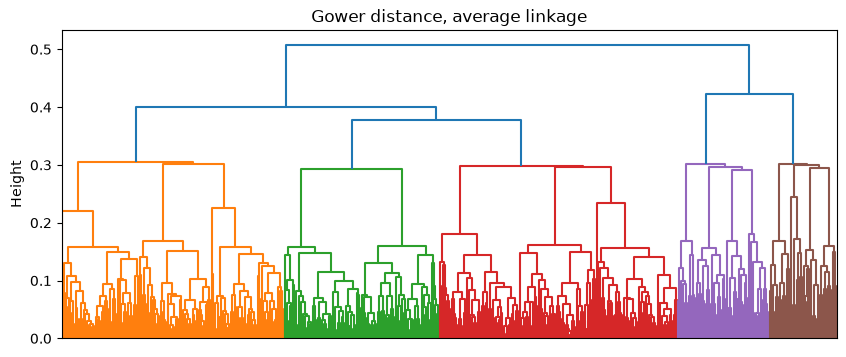

In [35]:
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(linkage(squareform(G, checks=False), method="average"), no_labels=True, ax=ax)
ax.set(title="Gower distance, average linkage", ylabel="Height")
plt.show()

**2a - For each solution, which variables decide the clusters?**

**Average linkage splits into non-smokers (1,064), male smokers (159), and female smokers (115). Complete linkage splits into smokers (274), male non-smokers (517), and female non-smokers (547). Either way, sex and smoker decide the clusters. Region, age, BMI, and children are about the same in every cluster.**

**2b - Using your answer to Q1, explain why the categorical variables dominate the clusters.**

**A categorical mismatch adds a full 1 to the distance, while two people usually differ by much less than that on a numeric variable. So people with the same sex and smoker status end up much closer than people who differ, and the clusters form around those categories.**

#### c. Two fixes

In [36]:
# (i) drop sex from the distance
G_nosex = gower_matrix(ins, ins_num, ["smoker", "region"])
lab_nosex = gower_clusters(G_nosex, "average")
describe_clusters(lab_nosex, "(i) Drop sex, average linkage, K = 3")

# (ii) keep all six variables, weight each categorical variable 0.5
G_w = gower_matrix(ins, ins_num, ins_cat, weights={c: 0.5 for c in ins_cat})
lab_w = gower_clusters(G_w, "average")
describe_clusters(lab_w, "(ii) Categorical weights of 0.5, average linkage, K = 3")

===== (i) Drop sex, average linkage, K = 3 =====


,n,age,bmi,children
cluster,,,,
1,365,38.9,33.3,1.1
2,324,39.3,29.2,1.0
3,649,39.3,29.9,1.1


sex,female,male
cluster,,
1,176,189
2,161,163
3,325,324


smoker,no,yes
cluster,,
1,274,91
2,257,67
3,533,116


region,northeast,northwest,southeast,southwest
cluster,,,,
1,0,1,364,0
2,324,0,0,0
3,0,324,0,325


===== (ii) Categorical weights of 0.5, average linkage, K = 3 =====


,n,age,bmi,children
cluster,,,,
1,10,33.1,28.4,5.0
2,268,38.1,30.8,1.1
3,1060,39.5,30.6,1.1


sex,female,male
cluster,,
1,3,7
2,109,159
3,550,510


smoker,no,yes
cluster,,
1,9,1
2,0,268
3,1055,5


region,northeast,northwest,southeast,southwest
cluster,,,,
1,0,0,3,7
2,67,53,91,57
3,257,272,270,261


**2c - What impact does each of these fixes have?**

**(i) Dropping sex just moves the problem. The clusters are now decided by region (southeast, northeast, northwest + southwest), and smoker is mixed across them. (ii) With weights of 0.5, smoker and the numeric variables finally matter. Cluster 2 is 268 smokers, a tiny cluster of 10 has about 5 children each, and the other 1,060 people are one big cluster. It is better, but the clusters are very uneven.**

### 3. K-prototypes

#### a. Default gamma

In [37]:
kp = KPrototypes(n_clusters=3, init="Huang", n_init=10, random_state=0).fit(X_mixed, categorical=cat_idx)
print(f"gamma used: {kp.gamma:.4f}")
lab_kp = kp.labels_ + 1
describe_clusters(lab_kp, "K-prototypes, default gamma")

gamma used: 0.5000
===== K-prototypes, default gamma =====


,n,age,bmi,children
cluster,,,,
1,460,52.8,31.6,0.5
2,387,40.2,30.9,2.7
3,491,25.7,29.6,0.4


sex,female,male
cluster,,
1,253,207
2,177,210
3,232,259


smoker,no,yes
cluster,,
1,378,82
2,301,86
3,385,106


region,northeast,northwest,southeast,southwest
cluster,,,,
1,127,98,118,117
2,82,112,96,97
3,115,115,150,111


**3a - What value of gamma did it use? Which variables decide the clusters now?**

**gamma = 0.5. Now the numeric variables decide the clusters: cluster 1 is older (52.8) with few children, cluster 2 has the most children (2.7) and is about 40, and cluster 3 is the youngest (25.7). Sex, smoker, and region are about evenly mixed in every cluster.**

#### b. gamma = 10

In [38]:
kp10 = KPrototypes(n_clusters=3, init="Huang", n_init=10, gamma=10, random_state=0).fit(X_mixed, categorical=cat_idx)
lab_kp10 = kp10.labels_ + 1
describe_clusters(lab_kp10, "K-prototypes, gamma = 10")

===== K-prototypes, gamma = 10 =====


,n,age,bmi,children
cluster,,,,
1,608,42.0,30.4,1.1
2,459,34.3,29.1,1.0
3,271,41.2,33.8,1.2


sex,female,male
cluster,,
1,545,63
2,68,391
3,49,222


smoker,no,yes
cluster,,
1,553,55
2,428,31
3,83,188


region,northeast,northwest,southeast,southwest
cluster,,,,
1,153,227,139,89
2,125,69,51,214
3,46,29,174,22


**3b - How do the clusters change with gamma = 10?**

**With gamma = 10 the categorical variables decide the clusters. Cluster 1 is mostly women who don't smoke, cluster 2 is mostly men who don't smoke (many in the southwest), and cluster 3 is mostly smokers (188 of 271), mostly men from the southeast. Age and children barely differ between clusters.**

#### c. Size of the numeric part vs. gamma

In [39]:
# Numeric part of the K-prototypes distance: squared distance from each person to their cluster's numeric center
centers = np.array(kp.cluster_centroids_)[:, :3].astype(float)     # numeric columns come first
Xnum = X_mixed[ins_num].to_numpy()
sq_dist = ((Xnum - centers[kp.labels_]) ** 2).sum(axis=1)

print(f"Average squared numeric distance to own cluster center: {sq_dist.mean():.3f}")
print(f"gamma (cost of one categorical mismatch):               {kp.gamma:.3f}")

Average squared numeric distance to own cluster center: 1.623
gamma (cost of one categorical mismatch):               0.500


**3c - How much does a mismatch count in K-prototypes with the default gamma? Why did Gower and K-prototypes give such different clusters?**

**The average squared numeric distance to the cluster center is 1.62, while one mismatch only costs gamma = 0.5. So a mismatch counts for less than a third of a typical numeric distance, and the numeric variables win. Gower is the opposite: a mismatch costs a full 1 on the same scale where numeric differences are mostly small, so the categorical variables win.**

### 4. Which clustering is useful?

In [40]:
solutions = {"Gower, average linkage (2a)": lab_avg,
             "Gower, cat. weights 0.5 (2c)": lab_w,
             "K-prototypes, default gamma (3a)": lab_kp,
             "K-prototypes, gamma = 10 (3b)": lab_kp10}

tables = []
for name, lab in solutions.items():
    d = ins.assign(cluster=lab)
    t = d.groupby("cluster").agg(n=("charges", "size"),
                                 mean_charges=("charges", "mean"),
                                 median_charges=("charges", "median"),
                                 smokers=("smoker", lambda s: (s == "yes").sum()))
    t.index = pd.MultiIndex.from_product([[name], t.index])
    tables.append(t)
pd.concat(tables).round(0)

n  mean_charges  median_charges  \
                                 cluster                                       
Gower, average linkage (2a)      1        1064        8434.0          7345.0   
                                 2         159       33042.0         36085.0   
                                 3         115       30679.0         28950.0   
Gower, cat. weights 0.5 (2c)     1          10        8692.0          6660.0   
                                 2         268       32112.0         34645.0   
                                 3        1060        8550.0          7395.0   
K-prototypes, default gamma (3a) 1         460       16171.0         11753.0   
                                 2         387       14578.0          9302.0   
                                 3         491        9522.0          3867.0   
K-prototypes, gamma = 10 (3b)    1         608       11082.0          9413.0   
                                 2         459        8093.0          5484.0   
                                 3         271       26949.0         25382.0   

                                          smokers  
                                 cluster           
Gower, average linkage (2a)      1              0  
                                 2            159  
                                 3            115  
Gower, cat. weights 0.5 (2c)     1              1  
                                 2            268  
                                 3              5  
K-prototypes, default gamma (3a) 1             82  
                                 2             86  
                                 3            106  
K-prototypes, gamma = 10 (3b)    1             55  
                                 2             31  
                                 3            188

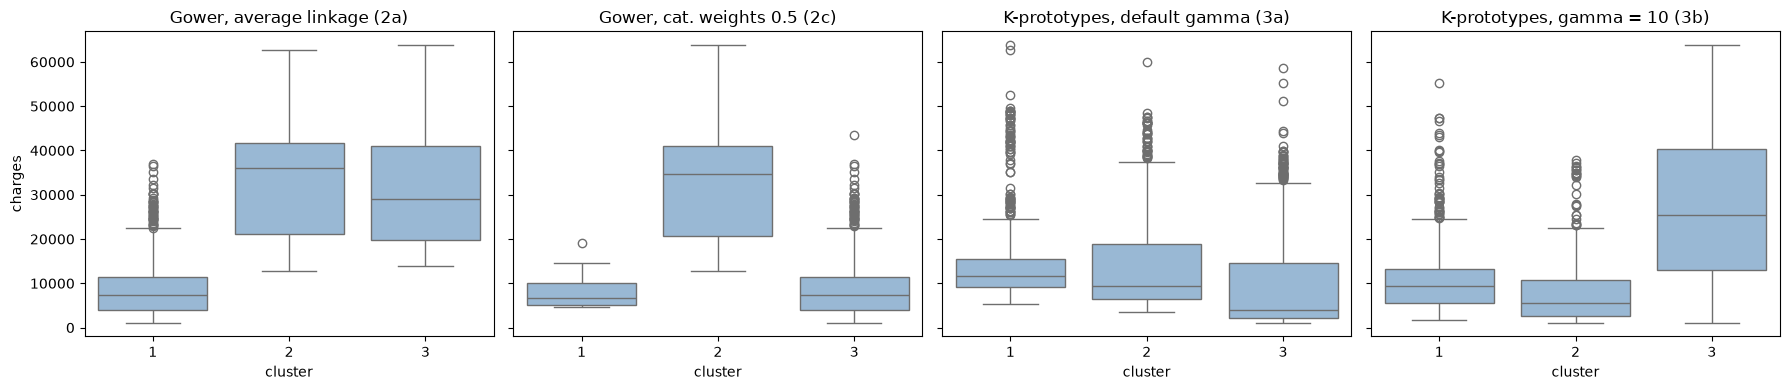

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, lab) in zip(axes, solutions.items()):
    sns.boxplot(x=lab, y=ins["charges"], ax=ax, color="#8FB8DE")
    ax.set(title=name, xlabel="cluster", ylabel="charges")
plt.tight_layout()
plt.show()

**4a - Which clustering separates people by charges best, and why? Does that make it the right clustering?**

**Gower with average linkage separates charges best. Cluster 1 has no smokers and a mean of $8,434, and clusters 2 and 3 are all smokers at about $33,042 and $30,679. Gower with weights of 0.5 is close behind, and K-prototypes with the default gamma separates charges worst because its clusters (means of $9.5k to $16.2k) overlap. That doesn't make it the right clustering. It only found smoker status, and clusters 2 and 3 differ just by sex, which adds nothing for charges. Charges were never used, so whether it is right depends on what we want the clusters for.**

**4b - What does this exercise tell you about choosing how much a categorical difference should count compared with a numeric one?**

**How much a categorical difference counts changes the clusters completely, and the data can't tell us the right amount. It has to be chosen based on what we want the clusters to do, and the choice (weights or gamma) should be reported and tested with a few values.**